# Handwritten Digit Classification using Machine Learning

## 1. Data Loading and Exploration

In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from sklearn.datasets import fetch_openml
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [4]:
mnist = fetch_openml('mnist_784', version=1, as_frame=False, parser='liac-arff')
print(type(mnist))
print(mnist.keys())

<class 'sklearn.utils._bunch.Bunch'>
dict_keys(['data', 'target', 'frame', 'categories', 'feature_names', 'target_names', 'DESCR', 'details', 'url'])


In [5]:
X = mnist.data
y = mnist.target

print(X.shape)
print(y.shape)

print(type(X))
print(type(y))

(70000, 784)
(70000,)
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>


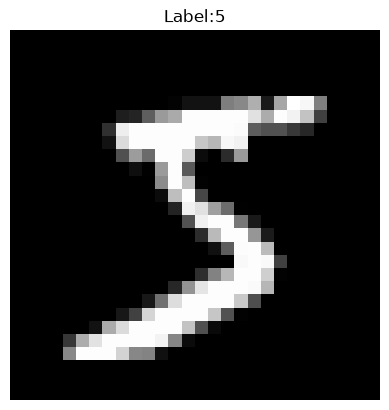

In [ ]:
image = X[0]

#original image is store as a 1D array (784,), so reshape to 28*28
plt.imshow(image.reshape(28,28), cmap='gray')

plt.title(f"Label:{y[0]}")
plt.axis('off')
plt.show()

In [7]:
print("First image shape: ", X[0].shape)
print("First 20 pixel values ", X[0][:20])

print("Minimum pixel value: ", X[0].min())
print("Maximum pixel value: ", X[0].max())

print("Actual digit label:", y[0])

First image shape:  (784,)
First 20 pixel values  [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Minimum pixel value:  0.0
Maximum pixel value:  255.0
Actual digit label: 5


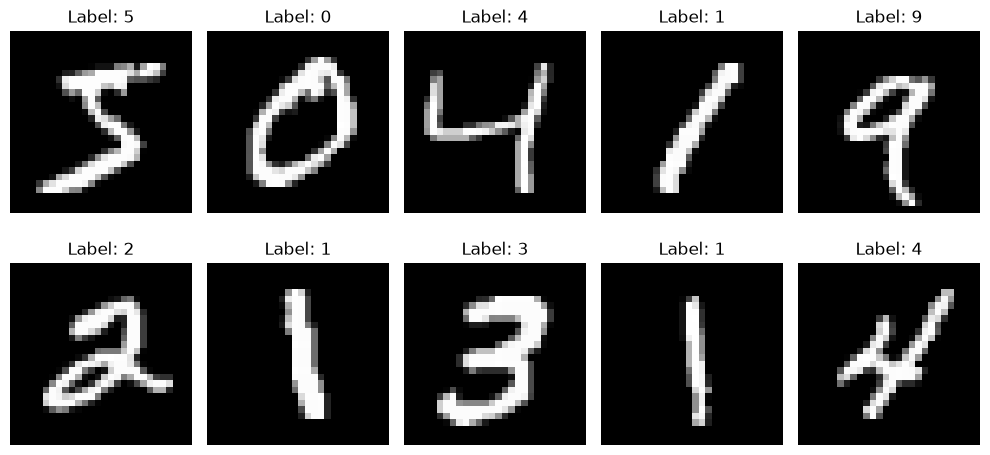

In [8]:
plt.figure(figsize=(10,5))

for i in range(10):
    plt.subplot(2, 5, i+1)
    plt.imshow(X[i].reshape(28,28), cmap='gray')
    plt.title(f"Label: {y[i]}")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
digits, counts = np.unique(y, return_counts=True)

for digit, count in zip(digits, counts):
    print(f"Digit {digit}: {count} images")

Digit 0: 6903 images
Digit 1: 7877 images
Digit 2: 6990 images
Digit 3: 7141 images
Digit 4: 6824 images
Digit 5: 6313 images
Digit 6: 6876 images
Digit 7: 7293 images
Digit 8: 6825 images
Digit 9: 6958 images


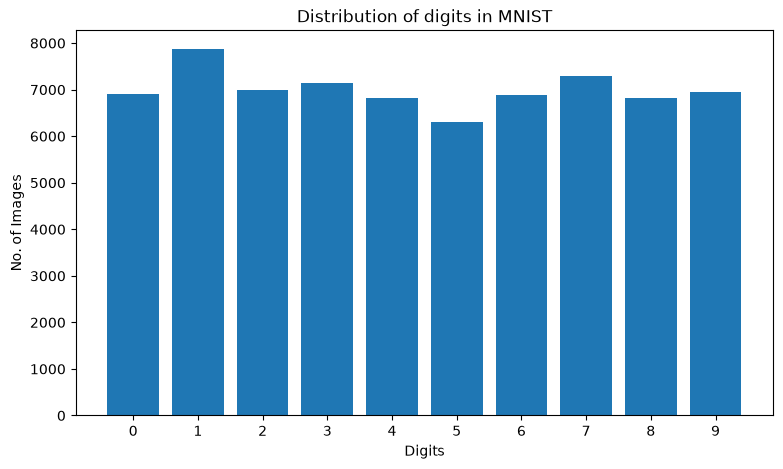

In [10]:
plt.figure(figsize=(9,5))

plt.bar(digits, counts)

plt.xlabel("Digits")
plt.ylabel("No. of Images")
plt.title("Distribution of digits in MNIST")
plt.xticks(digits)

plt.show()

## 2. Data Preprocessing

In [11]:
X_Normalized = X/255.0

print("Original minimum:", X.min())
print("Original maximum:", X.max())

print("Normalized minimum:", X_Normalized.min())
print("Normalized maximum:", X_Normalized.max())

print("Original Sample:", X[0][:10])
print("Normalized Sample:", X_Normalized[0][:10])

print("Original shape:", X.shape)
print("Normalized shape:", X_Normalized.shape)

print("Original data type:", X.dtype)
print("Normalized data type:", X_Normalized.dtype)


Original minimum: 0.0
Original maximum: 255.0
Normalized minimum: 0.0
Normalized maximum: 1.0
Original Sample: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Normalized Sample: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Original shape: (70000, 784)
Normalized shape: (70000, 784)
Original data type: float64
Normalized data type: float64


In [12]:
print("First 10 labels:", y[:10])
print("Labels around position 60000:", y[59995:60005])
print("Last 10 labels:", y[-10:])

X_train = X_Normalized[:60000]
X_test = X_Normalized[60000:]

y_train = y[:60000]
y_test = y[60000:]

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)


First 10 labels: ['5' '0' '4' '1' '9' '2' '1' '3' '1' '4']
Labels around position 60000: ['8' '3' '5' '6' '8' '7' '2' '1' '0' '4']
Last 10 labels: ['7' '8' '9' '0' '1' '2' '3' '4' '5' '6']
Training features: (60000, 784)
Testing features: (10000, 784)
Training labels: (60000,)
Testing labels: (10000,)


In [13]:
print("Total images:", len(X_train) + len(X_test))
print("Training percentage:", len(X_train) / 70000 * 100)
print("Testing percentage:", len(X_test) / 70000 * 100)

Total images: 70000
Training percentage: 85.71428571428571
Testing percentage: 14.285714285714285


In [14]:
y_train = y_train.astype(np.uint8)
y_test = y_test.astype(np.uint8)

print("Training labels:", y_train[:10])
print("Testing labels:", y_test[:10])

print("Training label dtype:", y_train.dtype)
print("Testing label dtype:", y_test.dtype)

Training labels: [5 0 4 1 9 2 1 3 1 4]
Testing labels: [7 2 1 0 4 1 4 9 5 9]
Training label dtype: uint8
Testing label dtype: uint8


## 3. Distance Metric Experimentation

In [ ]:
A = np.array([0, 0, 255, 255])
B = np.array([0, 0, 250, 250])
C = np.array([255, 255, 0, 0])

distance_AB = np.sqrt(np.sum((A - B) ** 2))

print("Distance between A and B:", distance_AB)

distance_AC = np.sqrt(np.sum((A - C) ** 2))

print("Distance between A and C:", distance_AC)

Distance between A and B: 7.0710678118654755
Distance between A and C: 510.0


In [16]:
image_1 = X_train[0]
image_2 = X_train[1]

distance = np.sqrt(np.sum((image_1-image_2)**2))

print("Image 1 label:", y_train[0])
print("Image 2 label:", y_train[1])
print("Eclidean Distance:", distance)

Image 1 label: 5
Image 2 label: 0
Eclidean Distance: 9.361222132577327


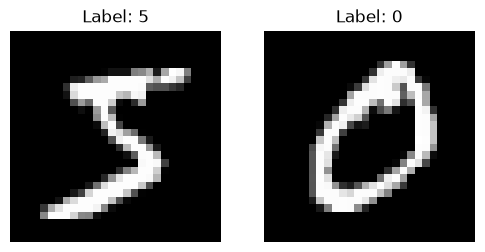

In [17]:
plt.figure(figsize=(6, 3))

plt.subplot(1, 2, 1)
plt.imshow(image_1.reshape(28, 28), cmap='gray')
plt.title(f"Label: {y_train[0]}")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(image_2.reshape(28, 28), cmap='gray')
plt.title(f"Label: {y_train[1]}")
plt.axis('off')

plt.show()

In [ ]:

print("Image 1 non-zero pixels:", np.count_nonzero(image_1))
print("Image 2 non-zero pixels:", np.count_nonzero(image_2))

common_zero = np.sum((image_1 == 0) & (image_2 == 0))

print("Common zero pixels:", common_zero)

different_pixels = np.sum(image_1 != image_2)

print("Different pixel positions:", different_pixels)

Image 1 non-zero pixels: 166
Image 2 non-zero pixels: 176
Common zero pixels: 541
Different pixel positions: 236


## 4. K-Nearest Neighbors Implementation

In [ ]:
knn = KNeighborsClassifier(n_neighbors=3)

knn.fit(X_train[:5000], y_train[:5000])

print("KNN model trained successfully!")

prediction = knn.predict(X_test[:1])

print("Actual digit", y_test[0])
print("Predicted digit", prediction[0])

KNN model trained successfully!
Actual digit 7
Predicted digit 7


## 5. Model Evaluation and Tuning

In [20]:
y_pred = knn.predict(X_test[:100])

correct = np.sum(y_pred == y_test[:100])

accuracy = correct/100 * 100

print("Correct Predictions:", correct)
print("Incorrect Predictions:", 100-correct)
print("Accuracy:", accuracy,"%")

Correct Predictions: 94
Incorrect Predictions: 6
Accuracy: 94.0 %


In [22]:
k_values = [1, 3, 5]

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train[:5000], y_train[:5000])
    predictions = model.predict(X_test[:100])
    accuracy = np.mean(predictions == y_test[:100])*100
    print(f"K = {k}, Accuracy = {accuracy:.2f}%")

K = 1, Accuracy = 90.00%
K = 3, Accuracy = 94.00%
K = 5, Accuracy = 95.00%


In [24]:
training_size = [5000, 10000, 20000]

for size in training_size:
    model = KNeighborsClassifier(n_neighbors=5)
    model.fit(X_train[:size], y_train[:size])
    predictions = model.predict(X_test[:100])
    accuracy = np.mean(predictions == y_test[:100])*100
    print(f"training size = {size}, Accuracy = {accuracy:.2f}%")

training size = 5000, Accuracy = 95.00%
training size = 10000, Accuracy = 95.00%
training size = 20000, Accuracy = 96.00%


## 6. Final Results

In [ ]:
knn = KNeighborsClassifier(n_neighbors=5)

start = time.time()
knn.fit(X_train[:20000], y_train[:20000])
end = time.time()

training_time = end - start

start = time.time()
predictions = knn.predict(X_test[:100])
end = time.time()

prediction_time = end - start

print("Training time:", round(training_time, 4), "seconds")
print("Prediction time:", round(prediction_time, 4), "seconds")


Training time: 0.0955 seconds
Prediction time: 0.0333 seconds


In [ ]:
knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train[:20000], y_train[:20000])

y_pred = knn.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("KNN Accuracy:", accuracy * 100, "%")

KNN Accuracy: 95.49 %


In [ ]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.95      0.99      0.97       980
           1       0.93      0.99      0.96      1135
           2       0.98      0.93      0.95      1032
           3       0.94      0.96      0.95      1010
           4       0.97      0.95      0.96       982
           5       0.96      0.95      0.95       892
           6       0.97      0.98      0.98       958
           7       0.95      0.95      0.95      1028
           8       0.98      0.89      0.94       974
           9       0.94      0.94      0.94      1009

    accuracy                           0.95     10000
   macro avg       0.96      0.95      0.95     10000
weighted avg       0.96      0.95      0.95     10000



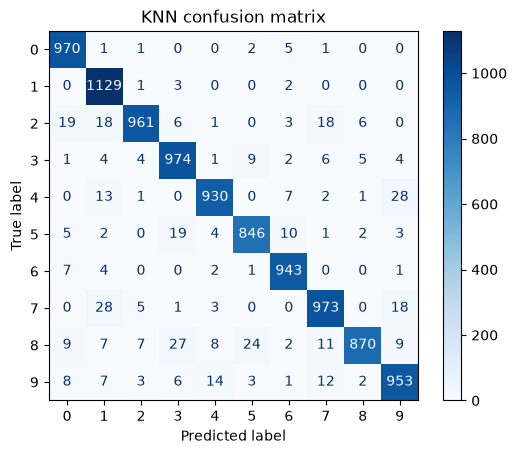

In [ ]:
cm = confusion_matrix(y_test, y_pred)

display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels = range(10)
)

display.plot(cmap='Blues', values_format='d')
plt.title("KNN confusion matrix")
plt.show()